# ЗС 6. Transfer learning көмегімен гүлдерді жіктеу

Деректер жиыны **tf_flowers** (`flower_photos`): 3 670 фотосурет, 5 класс — түймедақ, бақбақ, раушан, күнбағыс, қызғалдақ.

Төрт тәсілді салыстырамыз:

| Модель | Стратегия |
|---|---|
| Өз CNN | нөлден оқыту |
| EfficientNetB0 | белгілерді шығару (база мұздатылған) |
| EfficientNetB0 | жоғарғы қабаттарды қосымша оқыту (LR 1e-5) |
| ResNet50 | `layer4`-ті қосымша оқыту (Keras-та — `conv5_*` блогы, LR 1e-5) |



## 1. Деректер: train / val / test бөлу және аугментация

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Using 734 files for validation.
Кластар: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Батчтар  train/val/test: 92 11 12


W0000 00:00:1791266652.422888 53091984 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


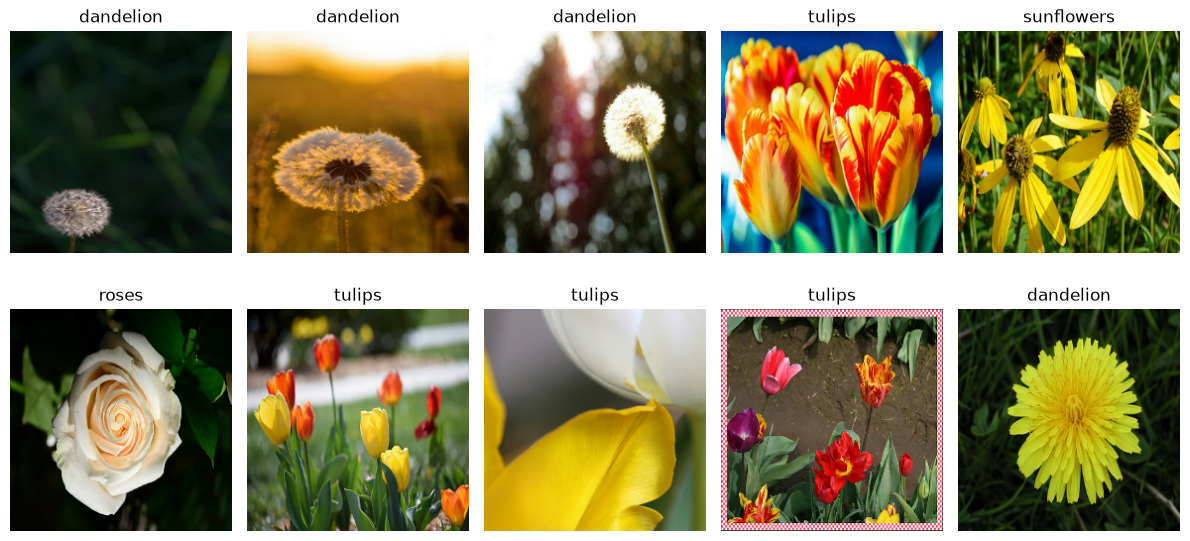

In [ ]:
import os, random, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
IMG_SIZE, BATCH = (224, 224), 32

train_ds, val_test_ds = keras.utils.image_dataset_from_directory(
    "flower_photos", validation_split=0.2, subset="both",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH)
class_names = train_ds.class_names
print("Кластар:", class_names)

# 20%-ды екіге бөлеміз: 10% val, 10% test (test тек соңында қолданылады)
n_vt = val_test_ds.cardinality().numpy()
val_ds  = val_test_ds.take(n_vt // 2)
test_ds = val_test_ds.skip(n_vt // 2)
print("Батчтар  train/val/test:", train_ds.cardinality().numpy(), val_ds.cardinality().numpy(), test_ds.cardinality().numpy())

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

# Аугментация — тек train кезінде 
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augment")

plt.figure(figsize=(12, 6))
for imgs, labels in val_ds.take(1):
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8")); plt.title(class_names[labels[i]]); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/samples.png", dpi=120); plt.show()

## 2. Көмекші функциялар

In [2]:
results = {}     # модель -> метрикалар
histories = {}

def count_params(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    total = int(sum(np.prod(w.shape) for w in model.weights))
    return trainable, total

def run(name, model, epochs, lr, patience=3, prev_epochs=0):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    trainable, total = count_params(model)
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=2,
                  callbacks=[keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True,
                                                           monitor="val_loss")])
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    results[name] = dict(trainable=trainable, total=total, val_acc=val_acc, test_acc=test_acc,
                         epochs=len(h.history["loss"]), seconds=time.time() - t0)
    histories[name] = h.history
    print(f"{name}: trainable={trainable:,}  val={val_acc:.4f}  test={test_acc:.4f}  "
          f"epochs={results[name]['epochs']}  time={results[name]['seconds']:.0f}s")
    return model

def plot_history(name, ax_loss, ax_acc):
    h = histories[name]
    ax_loss.plot(h["loss"], label="train"); ax_loss.plot(h["val_loss"], label="val")
    ax_loss.set_title(f"{name}\nloss"); ax_loss.set_xlabel("дәуір"); ax_loss.legend()
    ax_acc.plot(h["accuracy"], label="train"); ax_acc.plot(h["val_accuracy"], label="val")
    ax_acc.set_title("accuracy"); ax_acc.set_xlabel("дәуір"); ax_acc.legend()

def freeze_bn(model_or_layer):
    for l in model_or_layer.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False

## 3. Baseline: өз CNN-ді нөлден оқыту

In [3]:
def build_cnn():
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1 / 255)(x)
    for f in (32, 64, 128, 128):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(len(class_names), activation="softmax")(x)
    return keras.Model(inp, out, name="own_cnn")

cnn = build_cnn()
cnn.summary()
cnn = run("Өз CNN | нөлден", cnn, epochs=20, lr=1e-3, patience=5)

Model: "own_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,885 (948.77 KB)

 Trainable params: 242,181 (946.02 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/20


/Users/mackbook/projects/4kurs/comp-vision/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 - 44s - 481ms/step - accuracy: 0.4966 - loss: 1.3082 - val_accuracy: 0.2614 - val_loss: 2.0192
Epoch 2/20
92/92 - 43s - 466ms/step - accuracy: 0.5582 - loss: 1.1413 - val_accuracy: 0.2614 - val_loss: 2.1831
Epoch 3/20
92/92 - 42s - 454ms/step - accuracy: 0.6080 - loss: 1.0478 - val_accuracy: 0.2727 - val_loss: 2.3495
Epoch 4/20
92/92 - 42s - 453ms/step - accuracy: 0.6335 - loss: 0.9720 - val_accuracy: 0.2898 - val_loss: 2.2212
Epoch 5/20
92/92 - 43s - 466ms/step - accuracy: 0.6434 - loss: 0.9439 - val_accuracy: 0.4176 - val_loss: 1.4429
Epoch 6/20
92/92 - 41s - 451ms/step - accuracy: 0.6608 - loss: 0.8832 - val_accuracy: 0.4375 - val_loss: 1.3230
Epoch 7/20
92/92 - 42s - 459ms/step - accuracy: 0.6788 - loss: 0.8540 - val_accuracy: 0.5994 - val_loss: 0.9888
Epoch 8/20
92/92 - 44s - 474ms/step - accuracy: 0.6815 - loss: 0.8359 - val_accuracy: 0.5994 - val_loss: 1.0442
Epoch 9/20
92/92 - 44s - 475ms/step - accuracy: 0.6972 - loss: 0.8094 - val_accuracy: 0.6676 - val_loss: 0.8640
Epo

## 4. EfficientNetB0: белгілерді шығару (база мұздатылған)

In [4]:
def build_transfer(base, preprocess=None, name="model"):
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    if preprocess is not None:
        x = preprocess(x)
    x = base(x, training=False)          # BN статистикасы өзгермейді
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(class_names), activation="softmax")(x)
    return keras.Model(inp, out, name=name)

# Keras EfficientNetB0 ішінде нормализация бар (кіріс 0..255)
eff_base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
eff_base.trainable = False
eff = build_transfer(eff_base, name="effnet_b0")
eff = run("EfficientNetB0 | белгілерді шығару", eff, epochs=10, lr=1e-3, patience=3)

Epoch 1/10
92/92 - 20s - 218ms/step - accuracy: 0.6870 - loss: 0.8679 - val_accuracy: 0.8807 - val_loss: 0.4076
Epoch 2/10
92/92 - 16s - 178ms/step - accuracy: 0.8508 - loss: 0.4592 - val_accuracy: 0.9119 - val_loss: 0.2986
Epoch 3/10
92/92 - 17s - 185ms/step - accuracy: 0.8832 - loss: 0.3577 - val_accuracy: 0.9062 - val_loss: 0.2578
Epoch 4/10
92/92 - 16s - 178ms/step - accuracy: 0.9009 - loss: 0.3048 - val_accuracy: 0.9148 - val_loss: 0.2374
Epoch 5/10
92/92 - 18s - 197ms/step - accuracy: 0.9087 - loss: 0.2836 - val_accuracy: 0.9148 - val_loss: 0.2300
Epoch 6/10
92/92 - 17s - 185ms/step - accuracy: 0.9101 - loss: 0.2601 - val_accuracy: 0.9205 - val_loss: 0.2227
Epoch 7/10
92/92 - 21s - 232ms/step - accuracy: 0.9206 - loss: 0.2458 - val_accuracy: 0.9205 - val_loss: 0.2182
Epoch 8/10
92/92 - 26s - 277ms/step - accuracy: 0.9186 - loss: 0.2397 - val_accuracy: 0.9261 - val_loss: 0.2166
Epoch 9/10
92/92 - 26s - 280ms/step - accuracy: 0.9292 - loss: 0.2188 - val_accuracy: 0.9261 - val_loss:

## 5. EfficientNetB0: жоғарғы қабаттарды қосымша оқыту (LR 1e-5)

In [5]:
# Мұздатылған басты оқытқан модельді жалғастырамыз: соңғы 20 қабатты ашамыз, BN мұздатылған күйде қалады
eff_base.trainable = True
for l in eff_base.layers[:-20]:
    l.trainable = False
freeze_bn(eff_base)
print("Ашылған қабаттар:", sum(l.trainable for l in eff_base.layers), "/", len(eff_base.layers))
eff = run("EfficientNetB0 | жоғарғы қабаттар", eff, epochs=10, lr=1e-5, patience=3)

Ашылған қабаттар: 15 / 238
Epoch 1/10
92/92 - 37s - 406ms/step - accuracy: 0.9343 - loss: 0.2017 - val_accuracy: 0.9233 - val_loss: 0.2031
Epoch 2/10
92/92 - 34s - 369ms/step - accuracy: 0.9397 - loss: 0.1833 - val_accuracy: 0.9233 - val_loss: 0.2002
Epoch 3/10
92/92 - 33s - 359ms/step - accuracy: 0.9418 - loss: 0.1819 - val_accuracy: 0.9261 - val_loss: 0.1965
Epoch 4/10
92/92 - 32s - 348ms/step - accuracy: 0.9414 - loss: 0.1731 - val_accuracy: 0.9261 - val_loss: 0.1947
Epoch 5/10
92/92 - 29s - 318ms/step - accuracy: 0.9404 - loss: 0.1707 - val_accuracy: 0.9261 - val_loss: 0.1933
Epoch 6/10
92/92 - 29s - 314ms/step - accuracy: 0.9472 - loss: 0.1619 - val_accuracy: 0.9290 - val_loss: 0.1872
Epoch 7/10
92/92 - 28s - 310ms/step - accuracy: 0.9421 - loss: 0.1640 - val_accuracy: 0.9290 - val_loss: 0.1861
Epoch 8/10
92/92 - 28s - 303ms/step - accuracy: 0.9435 - loss: 0.1521 - val_accuracy: 0.9318 - val_loss: 0.1865
Epoch 9/10
92/92 - 29s - 312ms/step - accuracy: 0.9499 - loss: 0.1491 - val_a

## 6. ResNet50: `layer4` (Keras-та `conv5_*`) қосымша оқыту

In [6]:
res_base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
res_base.trainable = False
res = build_transfer(res_base, preprocess=layers.Lambda(keras.applications.resnet50.preprocess_input), name="resnet50")

# 1-кезең: бас қана оқытылады (кездейсоқ бас градиентпен базаны бұзбауы үшін)
res = run("ResNet50 | бас (кезең 1)", res, epochs=6, lr=1e-3, patience=3)

# 2-кезең: layer4 ≡ conv5 блогын ашамыз
res_base.trainable = True
for l in res_base.layers:
    l.trainable = l.name.startswith("conv5_")
freeze_bn(res_base)
print("Ашылған қабаттар:", sum(l.trainable for l in res_base.layers), "/", len(res_base.layers))
res = run("ResNet50 | layer4 (conv5)", res, epochs=10, lr=1e-5, patience=3)

Epoch 1/6
92/92 - 69s - 755ms/step - accuracy: 0.7163 - loss: 0.7767 - val_accuracy: 0.8750 - val_loss: 0.3284
Epoch 2/6
92/92 - 51s - 549ms/step - accuracy: 0.8488 - loss: 0.4158 - val_accuracy: 0.9006 - val_loss: 0.2973
Epoch 3/6
92/92 - 50s - 539ms/step - accuracy: 0.8825 - loss: 0.3265 - val_accuracy: 0.9062 - val_loss: 0.3033
Epoch 4/6
92/92 - 48s - 526ms/step - accuracy: 0.8999 - loss: 0.2816 - val_accuracy: 0.9034 - val_loss: 0.2735
Epoch 5/6
92/92 - 49s - 528ms/step - accuracy: 0.9012 - loss: 0.2639 - val_accuracy: 0.9148 - val_loss: 0.2783
Epoch 6/6
92/92 - 49s - 531ms/step - accuracy: 0.9213 - loss: 0.2357 - val_accuracy: 0.9148 - val_loss: 0.2953
ResNet50 | бас (кезең 1): trainable=10,245  val=0.9034  test=0.8927  epochs=6  time=326s
Ашылған қабаттар: 22 / 175
Epoch 1/10
92/92 - 73s - 789ms/step - accuracy: 0.9172 - loss: 0.2404 - val_accuracy: 0.9290 - val_loss: 0.2562
Epoch 2/10
92/92 - 68s - 738ms/step - accuracy: 0.9366 - loss: 0.1749 - val_accuracy: 0.9318 - val_loss: 0

## 7. Нәтиже кестесі

In [7]:
final = {
    "Өз CNN":          ("нөлден оқыту",                       "Өз CNN | нөлден"),
    "EfficientNetB0 ": ("белгілерді шығару",                  "EfficientNetB0 | белгілерді шығару"),
    "EfficientNetB0":  ("жоғарғы қабаттарды қосымша оқыту",   "EfficientNetB0 | жоғарғы қабаттар"),
    "ResNet50":        ("layer4-ті қосымша оқыту",            "ResNet50 | layer4 (conv5)"),
}
rows = []
for model_name, (strategy, key) in final.items():
    r = results[key]
    rows.append({"Модель": model_name.strip(), "Стратегия": strategy,
                 "Оқыт. параметрлер": f"{r['trainable']:,}".replace(",", " "),
                 "Val acc": f"{r['val_acc']*100:.1f} %", "Test acc": f"{r['test_acc']*100:.1f} %",
                 "Дәуір": r["epochs"]})
table = pd.DataFrame(rows)
table.to_csv(f"{OUTPUT_DIR}/results_table.csv", index=False)
table

,Модель,Стратегия,Оқыт. параметрлер,Val acc,Test acc,Дәуір
0,Өз CNN,нөлден оқыту,242 181,80.4 %,76.4 %,20
1,EfficientNetB0,белгілерді шығару,6 405,92.0 %,92.7 %,10
2,EfficientNetB0,жоғарғы қабаттарды қосымша оқыту,1 349 173,92.9 %,93.2 %,10
3,ResNet50,layer4-ті қосымша оқыту,14 963 717,93.2 %,90.8 %,5


## 8. Графиктер: loss және accuracy (train/val)

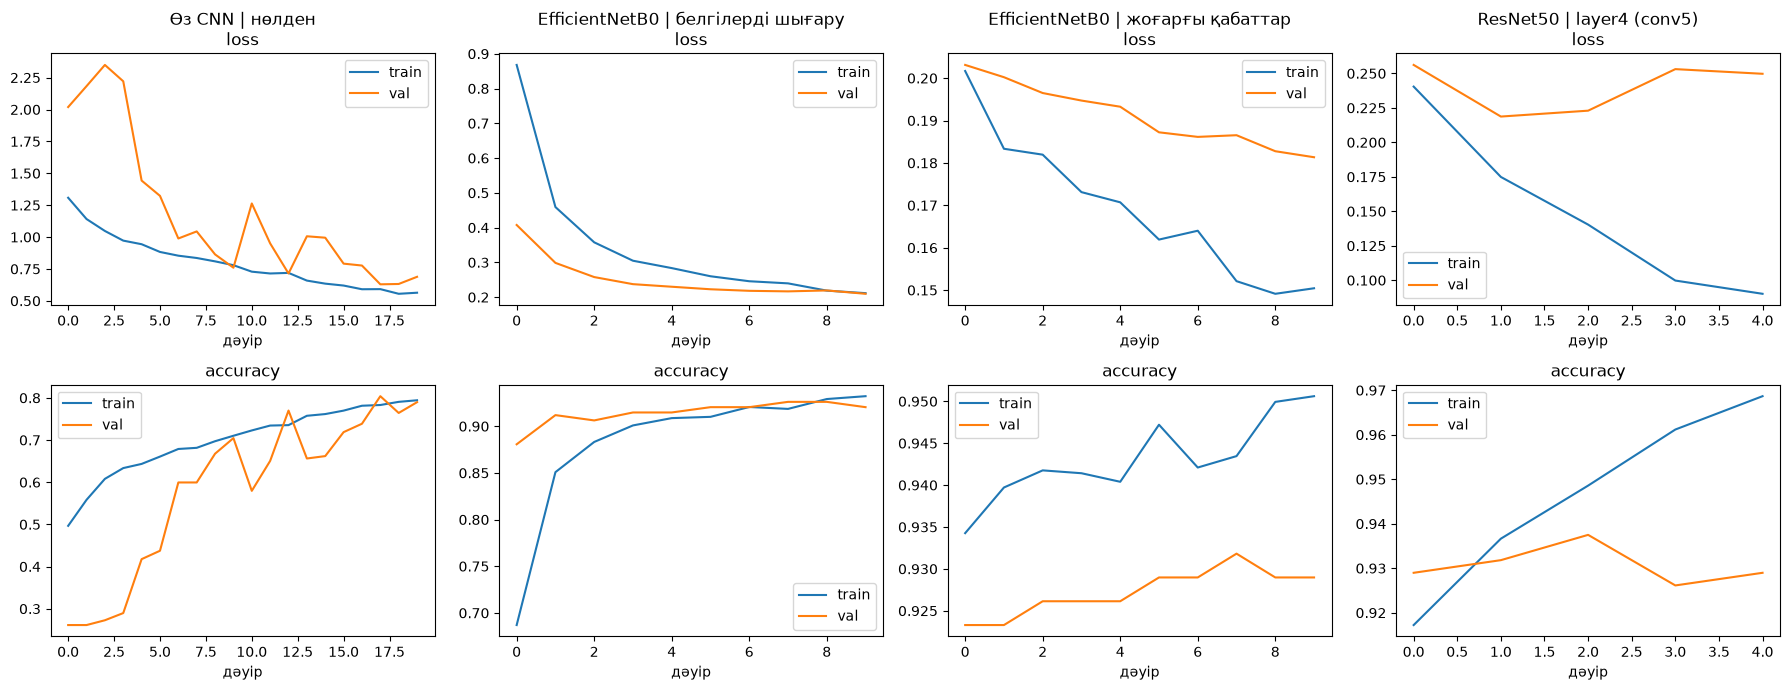

In [8]:
keys = ["Өз CNN | нөлден", "EfficientNetB0 | белгілерді шығару",
        "EfficientNetB0 | жоғарғы қабаттар", "ResNet50 | layer4 (conv5)"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, k in enumerate(keys):
    plot_history(k, axes[0, j], axes[1, j])
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=120); plt.show()

## 9. Ең жақсы модельдің қателер матрицасы

Ең жақсы модель (test acc бойынша): EfficientNetB0 | жоғарғы қабаттар


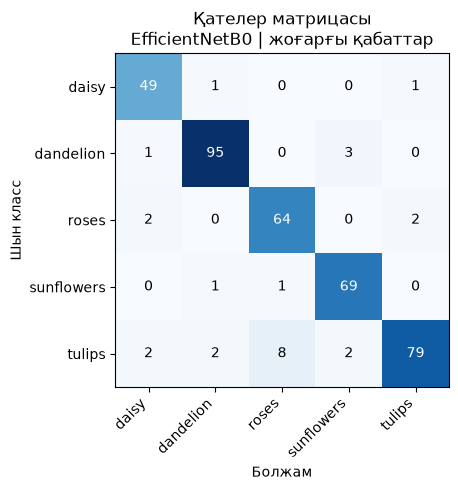

tulips → roses: 8 рет
dandelion → sunflowers: 3 рет
tulips → sunflowers: 2 рет
Test accuracy: 0.9319371727748691
Test өлшемі: 382


In [9]:
models = {"Өз CNN | нөлден": cnn, "EfficientNetB0 | жоғарғы қабаттар": eff, "ResNet50 | layer4 (conv5)": res}
best_key = max(models, key=lambda k: results[k]["test_acc"])
best = models[best_key]
print("Ең жақсы модель (test acc бойынша):", best_key)

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = best.predict(test_ds, verbose=0).argmax(1)
cm = tf.math.confusion_matrix(y_true, y_pred, num_classes=len(class_names)).numpy()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(5), class_names, rotation=45, ha="right"); ax.set_yticks(range(5), class_names)
for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Болжам"); ax.set_ylabel("Шын класс"); ax.set_title(f"Қателер матрицасы\n{best_key}")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/confusion_matrix.png", dpi=120); plt.show()

# Қай кластар шатасады
off = [(cm[i, j], class_names[i], class_names[j]) for i in range(5) for j in range(5) if i != j]
for n, a, b in sorted(off, reverse=True)[:3]:
    print(f"{a} → {b}: {n} рет")
print("Test accuracy:", (y_true == y_pred).mean())
print("Test өлшемі:", len(y_true))